# Linear day-ahead models

Hourly CAISO carbon intensity, in gCO₂/kWh. The number is estimated from the fuel mix, so fuel generation, fuel shares, and net generation are not inputs.

This notebook asks how far a linear model gets when it may only use what is known about a day ahead: the clock, carbon at this hour yesterday and last week, yesterday's temperature, radiation, Fresno radiation, and wind, and CAISO's day-ahead demand forecast.

A separate coefficient for each hour matches the diurnal shape, which is a level for each hour rather than a smooth wave. Ridge is included because mean radiation and Fresno radiation move together. Elastic net can drop one of a collinear pair; an `l1_ratio` of 1 is lasso. The sine/cosine clock is the compact alternative, and it can only draw a smooth daily wave.

Settings are chosen by forward validation inside the training period, minimizing MAE. The last 28 days are scored once.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

from sklearn.linear_model import ElasticNet, LinearRegression, Ridge

from src.modeling import (
    CYCLICAL_NUMERIC,
    DAY_AHEAD_CATEGORICAL,
    DAY_AHEAD_NUMERIC,
    cross_validated_mae,
    feature_matrix,
    linear_pipeline,
    search_time_series,
)

from src.carbon_data import load_model_frame
from src.modeling import TARGET, hour_climatology, result_row, score_predictions, train_test_split

frame = load_model_frame()
train, test = train_test_split(frame)
assert train.index.max() < test.index.min()
baseline = hour_climatology(train, test)
baseline_mae = score_predictions(test[TARGET], baseline)["mae"]
print(f"{len(frame)} hours, {frame.index.min():%Y-%m-%d} to {frame.index.max():%Y-%m-%d} UTC")
print(
    f"train {len(train)} hours through {train.index.max():%Y-%m-%d %H} UTC; "
    f"test {len(test)} hours from {test.index.min():%Y-%m-%d %H} UTC"
)
print(f"hour-of-day baseline MAE on the test block: {baseline_mae:.2f} g/kWh")


6793 hours, 2026-01-08 to 2026-10-18 UTC
train 6120 hours through 2026-09-20 22 UTC; test 673 hours from 2026-09-20 23 UTC
hour-of-day baseline MAE on the test block: 70.62 g/kWh


## Search

Ordinary least squares has no penalty. Ridge searches the penalty weight. Elastic net searches the penalty weight and the lasso share. Both encodings use the same day-ahead columns. The sine/cosine version replaces the hour and weekday dummies with a cycle, and keeps the day-of-year cycle that the dummy version already uses.

In [2]:
encodings = {
    "hour and weekday dummies": (DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC),
    "sine and cosine clock": ([], CYCLICAL_NUMERIC),
}
rows = []
predictions = {}
y_train = train[TARGET]
y_test = test[TARGET]
rows.append(
    result_row("hour-of-day mean", y_test, baseline, cv_mae=float("nan"), climatology_mae=baseline_mae)
    | {"detail": "training mean by local hour"}
)

for encoding, (categorical, numeric) in encodings.items():
    x_train = feature_matrix(train, categorical, numeric)
    x_test = feature_matrix(test, categorical, numeric)

    ordinary = linear_pipeline(LinearRegression(), categorical, numeric)
    cv_mae = cross_validated_mae(ordinary, x_train, y_train)
    ordinary.fit(x_train, y_train)
    predicted = ordinary.predict(x_test)
    name = f"least squares / {encoding}"
    predictions[name] = predicted
    rows.append(result_row(name, y_test, predicted, cv_mae, baseline_mae) | {"detail": "no penalty"})

    ridge = search_time_series(
        linear_pipeline(Ridge(), categorical, numeric),
        {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
        x_train,
        y_train,
    )
    predicted = ridge.predict(x_test)
    name = f"ridge / {encoding}"
    predictions[name] = predicted
    detail = ", ".join(f"{key.split('model__')[-1]}={value:g}" for key, value in ridge.best_params_.items())
    rows.append(result_row(name, y_test, predicted, -ridge.best_score_, baseline_mae) | {"detail": detail})

    elastic = search_time_series(
        linear_pipeline(ElasticNet(max_iter=20000, random_state=0), categorical, numeric),
        {"model__alpha": [0.001, 0.01, 0.1, 1.0], "model__l1_ratio": [0.5, 0.85, 1.0]},
        x_train,
        y_train,
    )
    predicted = elastic.predict(x_test)
    name = f"elastic net / {encoding}"
    predictions[name] = predicted
    detail = ", ".join(f"{key.split('model__')[-1]}={value:g}" for key, value in elastic.best_params_.items())
    rows.append(result_row(name, y_test, predicted, -elastic.best_score_, baseline_mae) | {"detail": detail})

table = pd.DataFrame(rows).sort_values("cv_mae", na_position="last").reset_index(drop=True)
winner = table.dropna(subset=["cv_mae"]).iloc[0]
print(
    f"Selected on forward validation: {winner['model']} ({winner['detail']}). "
    f"Test MAE {winner['mae']:.2f} g/kWh, {100 * winner['skill_vs_hour']:.1f}% below the hour-of-day mean."
)
table.round(3)


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-package

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-package

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-package

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-package

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-package

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-package

Selected on forward validation: elastic net / hour and weekday dummies (alpha=1, l1_ratio=1). Test MAE 24.86 g/kWh, 64.8% below the hour-of-day mean.


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-package

,model,mae,rmse,cv_mae,skill_vs_hour,detail
0,elastic net / hour and weekday dummies,24.863,31.140,21.139,0.648,"alpha=1, l1_ratio=1"
1,elastic net / sine and cosine clock,25.097,31.322,21.272,0.645,"alpha=1, l1_ratio=1"
2,ridge / sine and cosine clock,24.205,30.312,23.565,0.657,alpha=100
3,ridge / hour and weekday dummies,24.679,31.475,23.903,0.651,alpha=100
4,least squares / sine and cosine clock,24.361,30.508,30.769,0.655,no penalty
5,least squares / hour and weekday dummies,25.045,31.857,32.351,0.645,no penalty
6,hour-of-day mean,70.622,83.744,NaN,0.000,training mean by local hour


## What the selected model keeps

Numeric inputs are standardized, so a coefficient is the change in gCO₂/kWh for a one-standard-deviation move. A coefficient of zero was dropped by the penalty. Hour dummies are free to drop once yesterday's carbon is in the model, because that lag already carries the shape of the day.

In [3]:
selected = table.dropna(subset=["cv_mae"]).iloc[0]
encoding = "hour and weekday dummies" if "dummies" in selected["model"] else "sine and cosine clock"
categorical, numeric = {
    "hour and weekday dummies": (DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC),
    "sine and cosine clock": ([], CYCLICAL_NUMERIC),
}[encoding]
detail = {}
if selected["detail"] != "no penalty":
    detail = dict(part.split("=") for part in selected["detail"].split(", "))
if "least squares" in selected["model"]:
    estimator = LinearRegression()
elif "ridge" in selected["model"]:
    estimator = Ridge(alpha=float(detail["alpha"]))
else:
    estimator = ElasticNet(
        alpha=float(detail["alpha"]),
        l1_ratio=float(detail["l1_ratio"]),
        max_iter=20000,
        random_state=0,
    )
chosen = linear_pipeline(estimator, categorical, numeric)
chosen.fit(feature_matrix(train, categorical, numeric), y_train)
names = chosen.named_steps["pre"].get_feature_names_out()
coefficients = chosen.named_steps["model"].coef_
kept = (
    pd.DataFrame({"feature": names, "coefficient": coefficients})
    .loc[lambda frame: frame["coefficient"].abs() > 1e-6]
    .sort_values("coefficient", key=lambda values: values.abs(), ascending=False)
)
print(f"{selected['model']}: {len(kept)} of {len(coefficients)} coefficients kept")
kept.round(2)


elastic net / hour and weekday dummies: 8 of 38 coefficients kept


,feature,coefficient
31,num__carbon_lag_24,50.50
32,num__carbon_lag_168,10.40
37,num__demand_forecast_mwh,7.01
27,cat__dow_5,-3.73
36,num__wind_10m_lag_24,-3.31
33,num__temp_lag_24,-1.22
34,num__radiation_lag_24,-1.07
29,num__doy_sin,-0.46


## Where the clock encoding shows up

The left panel is validation MAE, which is what the selection uses. The right panel is the test residual averaged by local hour. A sine that cannot sit flat overnight leaves a systematic residual in those hours. The series below is the selected model against the actual daily mean on the holdout.

/var/folders/g2/mv6w8l9x5412btq20l7_rg3w0000gn/T/ipykernel_59617/2719093612.py:30: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout()


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  func(*args, **kwargs)


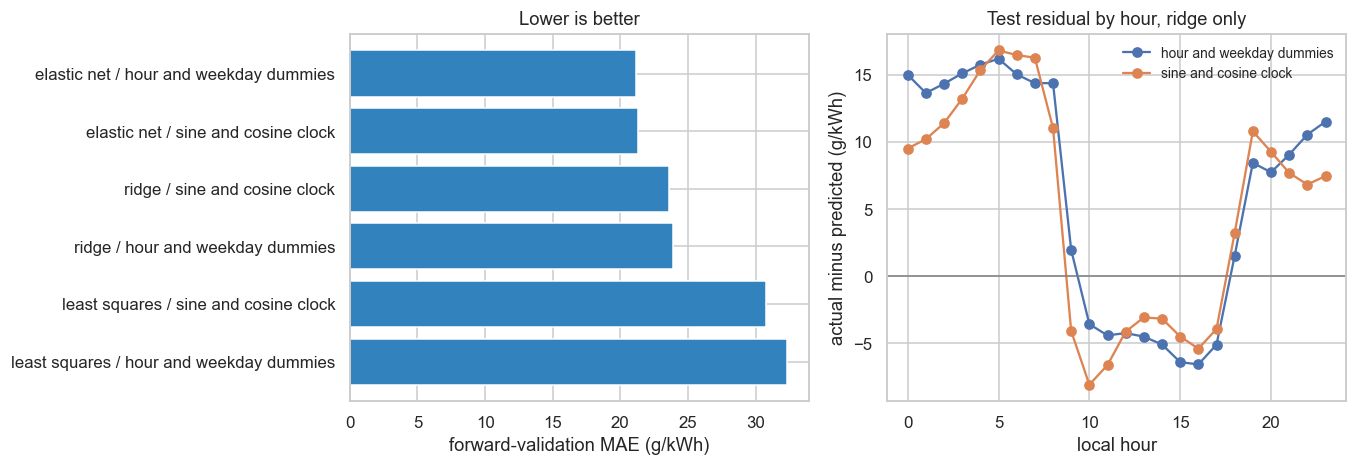

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


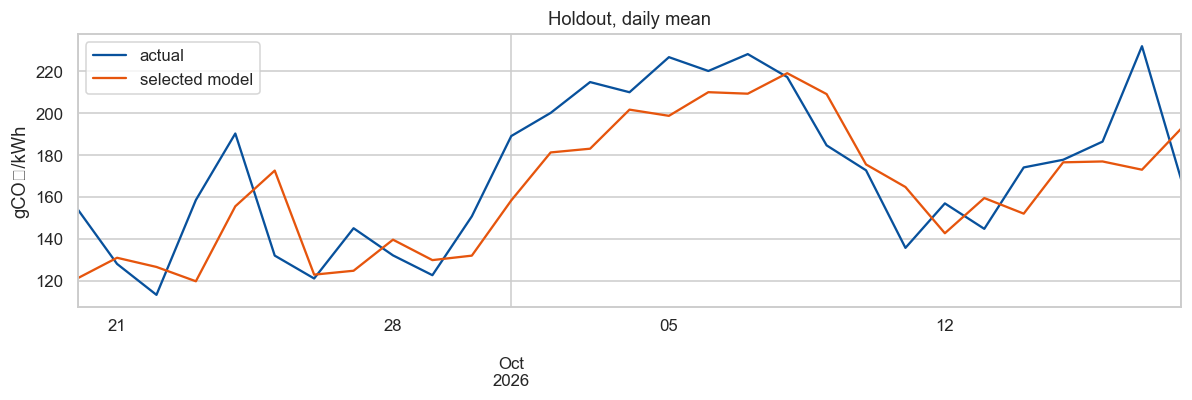

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
fitted = table.dropna(subset=["cv_mae"])
axes[0].barh(fitted["model"], fitted["cv_mae"], color="#3182bd")
axes[0].set_xlabel("forward-validation MAE (g/kWh)")
axes[0].set_title("Lower is better")
axes[0].invert_yaxis()

for name in ("ridge / hour and weekday dummies", "ridge / sine and cosine clock"):
    residual = y_test.to_numpy() - predictions[name]
    by_hour = pd.DataFrame({"hour": test["hour_local"].to_numpy(), "residual": residual})
    profile = by_hour.groupby("hour")["residual"].mean()
    axes[1].plot(profile.index, profile.values, marker="o", label=name.split(" / ")[1])
axes[1].axhline(0, color="0.5", lw=1)
axes[1].set_xlabel("local hour")
axes[1].set_ylabel("actual minus predicted (g/kWh)")
axes[1].set_title("Test residual by hour, ridge only")
axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout()

chosen = predictions[winner["model"]]
daily = pd.DataFrame(
    {"actual": y_test.to_numpy(), "selected model": chosen},
    index=test.index.tz_convert("America/Los_Angeles"),
).resample("D").mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
daily.plot(ax=ax, color=["#08519c", "#e6550d"])
ax.set_ylabel("gCO₂/kWh")
ax.set_title("Holdout, daily mean")
ax.set_xlabel("")
fig.tight_layout()
